<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Open Graph Metadata](https://github.com/Query-farm/vgi-opengraph)

Parse Open Graph, Twitter Card and HTML link-preview metadata from HTML text or URLs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-opengraph/blob/main/notebooks/02_keep_fetch_outcomes_before_selecting_previews.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-opengraph/blob/main/notebooks/README.md)


## 02 · Keep fetch outcomes before selecting previews

When a URL does not produce a preview title, did the page lack metadata, did HTTP fail, or was there no usable URL? A success-only result hides those distinctions. We keep every input, materialize the actual worker's fetch results once, and separate response status from a small title-selection rule.

**Explicit local fixture:** a Python HTTP server binds only to loopback and serves six authored paths. Nine URL input rows include a repeated URL, a redirect, empty metadata, HTTP 404, non-HTML content, malformed/unsupported URLs and NULL. The released worker performs real HTTP reads against that local server. No public website, image resource, real credentials or external account is contacted by the analysis.

### Decide whether a redirected result needs review

`REQUIRE_DIRECT=False` allows a returned title after a redirect. **True** additionally requires the returned final URL to equal the requested URL. Both rules require a supplied URL, no returned fetch error, a 2xx response and a nonmissing title.

This is a narrow illustrative rule. A direct response is not inherently trustworthy, a redirect is not inherently wrong, and a populated title is not a complete preview. Change only this Boolean for the final experiment.

In [1]:
REQUIRE_DIRECT = False  # Experiment: True; fetched responses and request audit stay fixed

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.22":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.22"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
import hashlib
import json
from pathlib import Path
from IPython.display import display
from vgi_notebooks import check_runtime, connect, theme, prose, prepare

check_runtime()
prepare("opengraph")
import opengraph_example as example

fixture_hash = example.verify_fixtures()
example.validate_switch(REQUIRE_DIRECT, "REQUIRE_DIRECT")
session = connect(globals())
theme()
site = example.FixtureSite()
FIXTURE_ORIGIN = site.base_url

### Fetch a bounded source once

The visible connection uses the native v0.1.0 release. `FIXTURE_ORIGIN` is only the ephemeral loopback address of the authored site. SQL reads the declared request list and materializes the scalar call before any display or selection. This avoids reissuing network calls when a result table is captured.

The duplicate `/article` input is retained. The worker deduplicates exact URL strings within one batch; we verify the observed request counts for this run without assuming deduplication across arbitrary batches or queries. NULL, malformed and unsupported inputs should produce no HTTP request.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'opengraph' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-opengraph@v0.1.0');
CREATE TABLE source_requests AS SELECT * FROM read_json_auto('fixtures/requests.json');
CREATE TABLE requests AS SELECT *,CASE WHEN starts_with(endpoint,'/')
 THEN '{{FIXTURE_ORIGIN}}'||endpoint ELSE endpoint END AS requested_url FROM source_requests;
CREATE TABLE fetched AS SELECT *,opengraph.main.fetch_opengraph(requested_url) AS result FROM requests;

,Count


In [5]:
observed_requests = site.save_audit()

In [6]:
%%sql request_audit <<
CREATE TABLE request_log AS SELECT * FROM read_json_auto('artifacts/request-log.json');
SELECT path,requests FROM request_log ORDER BY path;

In [7]:
display(request_audit)
prose(f"The server observed **{observed_requests} HTTP requests across {len(request_audit)} local paths**. `/article` was requested once for two source rows. `/go` plus its destination account for two requests. No card-image path was requested. These are observed network requests, not counts inferred from SQL result rows.")

,path,requests
0,/article,1
1,/binary,1
2,/empty,1
3,/final/story,1
4,/go,1
5,/missing,1


The server observed **6 HTTP requests across 6 local paths**. `/article` was requested once for two source rows. `/go` plus its destination account for two requests. No card-image path was requested. These are observed network requests, not counts inferred from SQL result rows.

### Response status is not metadata availability

Keep NULL URL input separate from a returned error structure. A 200 response with no title is different from a rejected 404 body. A non-HTML content type can produce an error even with HTTP 200. The worker returns the **final** response status after redirects, so the redirected row shows 200, not the intermediate 302.

The table replaces the ephemeral host/port with `LOCAL` for readable, stable display. Relative metadata URLs are resolved against the final response URL. They remain strings: the worker does not fetch the advertised image or verify a canonical identity.

In [8]:
%%sql response_table <<
CREATE TABLE response_evidence AS
SELECT request_id,label,requested_url IS NOT NULL AS url_available,result IS NOT NULL AS result_available,
 result.http_status AS http_status,result.content_type AS content_type,result.error AS error,
 result.title AS title,
 regexp_replace(requested_url,'^http://127[.]0[.]0[.]1:[0-9]+','LOCAL') AS requested_location,
 regexp_replace(result.final_url,'^http://127[.]0[.]0[.]1:[0-9]+','LOCAL') AS final_location,
 regexp_replace(result.image,'^http://127[.]0[.]0[.]1:[0-9]+','LOCAL') AS image_location,
 regexp_replace(result.url,'^http://127[.]0[.]0[.]1:[0-9]+','LOCAL') AS metadata_page_location,
 result.final_url IS DISTINCT FROM requested_url AS location_changed
FROM fetched;
SELECT request_id,label,http_status,error,title,requested_location,final_location,image_location
FROM response_evidence ORDER BY request_id;

In [9]:
display(response_table)
prose(f"**{int(response_table.error.notna().sum())} inputs** return an explicit error; **{int(response_table.http_status.eq(200).sum())} rows** have final HTTP 200. Those groups overlap at the non-HTML response. The redirected input resolves `card.png` to `LOCAL/final/card.png`; the error-page title is not selected as metadata.")

,request_id,label,http_status,error,title,requested_location,final_location,image_location
0,A,Direct HTML,200,None,Local article,LOCAL/article,LOCAL/article,LOCAL/cards/article.png
1,B,Repeated direct URL,200,None,Local article,LOCAL/article,LOCAL/article,LOCAL/cards/article.png
2,C,Redirected HTML,200,None,Redirect destination,LOCAL/go,LOCAL/final/story,LOCAL/final/card.png
3,D,HTML without metadata,200,None,None,LOCAL/empty,LOCAL/empty,None
4,E,HTTP 404,404,HTTP 404 Not Found,None,LOCAL/missing,LOCAL/missing,None
5,F,Non-HTML response,200,not an HTML page (content type image/png),None,LOCAL/binary,LOCAL/binary,None
6,G,Malformed URL,<NA>,invalid URL: not a URL,None,not a URL,None,None
7,H,Unsupported scheme,<NA>,unsupported URL scheme 'file': only http and h...,None,file:///synthetic,None,None
8,I,Missing URL,<NA>,None,None,None,None,None


**4 inputs** return an explicit error; **5 rows** have final HTTP 200. Those groups overlap at the non-HTML response. The redirected input resolves `card.png` to `LOCAL/final/card.png`; the error-page title is not selected as metadata.

### Select titles without dropping failed inputs

Selection happens only against the materialized response table. The missing-URL case stays unavailable, the four explicit fetch rejections stay visible, and the supplied empty-metadata page stays distinct from both. The duplicate successful URL is still two input records; this chart is not a count of distinct pages or HTTP requests.

In [10]:
%%sql
CREATE TABLE decisions AS SELECT *,CASE
 WHEN NOT url_available THEN 'Missing URL'
 WHEN error IS NOT NULL OR http_status NOT BETWEEN 200 AND 299 THEN 'Fetch rejected'
 WHEN title IS NULL THEN 'No preview title'
 WHEN {{REQUIRE_DIRECT}} AND location_changed THEN 'Redirect needs review'
 ELSE 'Selected preview' END AS outcome FROM response_evidence;

,Count


In [11]:
%%sql outcome_counts <<
SELECT labels.outcome,count(d.request_id) AS input_rows
FROM (VALUES (1,'Selected preview'),(2,'Redirect needs review'),(3,'No preview title'),
 (4,'Fetch rejected'),(5,'Missing URL')) labels(position,outcome)
LEFT JOIN decisions d USING(outcome) GROUP BY labels.position,labels.outcome ORDER BY labels.position;

With `REQUIRE_DIRECT=False`, **3 of 9 URL input rows** are selected. The returned responses and six-request audit are fixed; this parameter changes only the treatment of the redirected title. No metadata is repaired and no URL is fetched again.

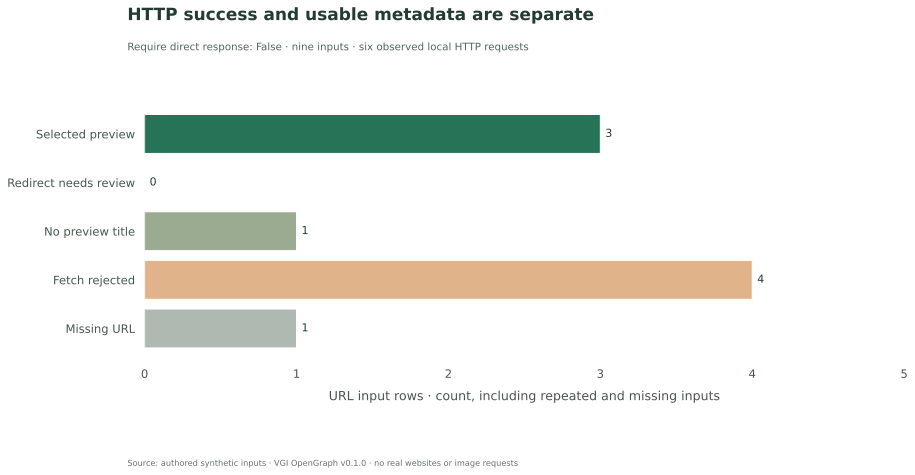

In [12]:
selected = int(outcome_counts.loc[outcome_counts.outcome.eq('Selected preview'),'input_rows'].iloc[0])
prose(f"With `REQUIRE_DIRECT={REQUIRE_DIRECT}`, **{selected} of 9 URL input rows** are selected. The returned responses and six-request audit are fixed; this parameter changes only the treatment of the redirected title. No metadata is repaired and no URL is fetched again.")
example.fetch_counts(outcome_counts,REQUIRE_DIRECT)

### Reconcile source rows, responses and observed requests

The checks confirm this finite fixture's accounting, including a repeated URL, final-URL resolution and failure retention. They do not exercise every charset, retry, timeout, response-size limit or TLS behavior. The local fixture makes the default reproducible; live websites can change content, redirect behavior and availability.

In [13]:
%%sql checks <<
SELECT 'nine unique input identities' AS check_name,count(*)=9 AND count(DISTINCT request_id)=9 AS passed FROM requests
UNION ALL SELECT 'all inputs retained',count(*)=9 FROM fetched
UNION ALL SELECT 'NULL URL remains NULL result',count(*)=1 FROM fetched WHERE requested_url IS NULL AND result IS NULL
UNION ALL SELECT 'four explicit errors',count(*)=4 FROM response_evidence WHERE error IS NOT NULL
UNION ALL SELECT 'five final HTTP 200 rows',count(*)=5 FROM response_evidence WHERE http_status=200
UNION ALL SELECT '404 body is not a title',count(*)=1 FROM response_evidence WHERE request_id='E' AND http_status=404 AND title IS NULL AND error IS NOT NULL
UNION ALL SELECT '200 non-HTML remains rejected',count(*)=1 FROM response_evidence WHERE request_id='F' AND http_status=200 AND error IS NOT NULL
UNION ALL SELECT 'empty successful page stays separate',count(*)=1 FROM response_evidence WHERE request_id='D' AND http_status=200 AND error IS NULL AND title IS NULL
UNION ALL SELECT 'redirect uses final URL for relative image',count(*)=1 FROM response_evidence WHERE request_id='C' AND final_location='LOCAL/final/story' AND image_location='LOCAL/final/card.png' AND metadata_page_location='LOCAL/final/story'
UNION ALL SELECT 'six observed requests on six paths',sum(requests)=6 AND count(*)=6 AND max(requests)=1 FROM request_log
UNION ALL SELECT 'duplicate inputs retain same result',count(DISTINCT CAST(result AS VARCHAR))=1 AND count(*)=2 FROM fetched WHERE request_id IN ('A','B')
UNION ALL SELECT 'policy selected three or two',count(*)=CASE WHEN {{REQUIRE_DIRECT}} THEN 2 ELSE 3 END FROM decisions WHERE outcome='Selected preview'
UNION ALL SELECT 'no rejected input is selected',count(*)=0 FROM decisions WHERE outcome='Selected preview' AND (error IS NOT NULL OR NOT url_available OR title IS NULL)
ORDER BY check_name;

In [14]:
display(checks)
assert len(checks)==13 and checks.passed.all()
assert site.save_audit()==observed_requests
prose(f"All **{len(checks)} source, response, policy and request checks** passed. Rechecking the server audit confirms that the later SQL did not add requests.")

,check_name,passed
0,200 non-HTML remains rejected,True
1,404 body is not a title,True
2,NULL URL remains NULL result,True
3,all inputs retained,True
4,duplicate inputs retain same result,True
5,empty successful page stays separate,True
6,five final HTTP 200 rows,True
7,four explicit errors,True
8,nine unique input identities,True
9,no rejected input is selected,True


All **13 source, response, policy and request checks** passed. Rechecking the server audit confirms that the later SQL did not add requests.

### Experiment: review redirected titles

Change only `REQUIRE_DIRECT` from **False to True**. Predict that selected input rows fall from three to two: the redirected row moves into review. The complete response table, final URL/image resolution, four explicit errors and six-path request audit must stay identical.

This does not assert that redirects are unsafe or that direct titles are trustworthy. It demonstrates how to make one selection rule explicit without confusing response failures, absent metadata and missing inputs. Restore False for the saved default.

In [15]:
session.close()
site.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-opengraph](https://github.com/Query-farm/vgi-opengraph)
